In [1]:
#1. Clonar codigo de github

!pip install -q lightgbm xgboost shap spacy tqdm scipy
!python -m spacy download es_core_news_sm

import os
BASE = '/content/phishing-estilometria-ia'
RAW = f'{BASE}/data/raw'
PROC = f'{BASE}/data/processed'
RES = f'{BASE}/results'
for d in [RAW, PROC, RES]:
    os.makedirs(d, exist_ok=True)

from google.colab import files
subidos = files.upload()
for nombre, contenido in subidos.items():
    with open(f'{RAW}/{nombre}', 'wb') as f:
        f.write(contenido)
os.listdir(RAW)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 48.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Saving parafrasis_ia.csv to parafrasis_ia (3).csv
Saving phishing_ia.csv to phishing_ia (3).csv
Saving legitimos.csv to legitimos (3).csv


['parafrasis_ia (1).csv',
 'phishing_ia (1).csv',
 'legitimos (2).csv',
 'phishing_ia (3).csv',
 'parafrasis_ia (2).csv',
 'phishing_ia.csv',
 'legitimos.csv',
 'parafrasis_ia.csv',
 'legitimos (3).csv',
 'parafrasis_ia (3).csv',
 'legitimos (1).csv',
 'phishing_ia (2).csv']

In [2]:
#2. configuración y normalización

import re, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
from scipy.stats import beta
warnings.filterwarnings('ignore')

SEED = 42
N_SPLITS = 5
N_BOOT = 1000
SHORT_WORDS = 60
CORTES = [0, 40, 70, 100, 130, 170, 10000]
ETIQ = ['0-40', '40-70', '70-100', '100-130', '130-170', '170+']
EXCLUIR_TAMANO = ['n_palabras', 'n_oraciones', 'n_saltos_linea']

EMOJI = re.compile('[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF\uFE0F\u200d]')

def normalizar(t):
    t = str(t)
    t = re.sub(r'^\s*\**Asunto\**\s*:\s*\**\s*', '', t, flags=re.I)
    t = re.sub(r'\[[^\]]*(enlace|link|url|ficticio)[^\]]*\]', '[URL]', t, flags=re.I)
    t = re.sub(r'https?://\S+|www\.\S+', '[URL]', t)
    t = re.sub(r'[\w\.\-+]+@[\w\-]+\.[\w\.\-]+', '[EMAIL]', t)
    t = re.sub(r'\[[^\]]*nombre[^\]]*\]', '', t, flags=re.I)
    t = re.sub(r'\b(Universidad Nacional de Ingeniería|UNI)\b', '[UNIVERSIDAD]', t)
    t = EMOJI.sub('', t)
    t = re.sub(r'[*_#]+', '', t)
    t = re.sub(r'[ \t]+', ' ', t)
    t = re.sub(r'\n{3,}', '\n\n', t)
    return t.strip()

def norm(t):
    return re.sub(r'\W+', ' ', t.lower()).strip()

def clave(t):
    return hashlib.md5(norm(normalizar(t)).encode()).hexdigest()

In [3]:
#3. construir el corpus (normaliza, deduplica, empareja por longitud, enlaza paráfrasis)

lg = pd.read_csv(f'{RAW}/legitimos.csv')
ph = pd.read_csv(f'{RAW}/phishing_ia.csv')

lg['text'] = lg['text'].map(normalizar)
ph['text'] = ph['text'].map(normalizar)
lg['label'], lg['generator'] = 0, 'humano'
ph['label'] = 1
ph['group'] = ph['scenario'].astype(str) + '|' + ph['tono'].astype(str)

def filtrar(df):
    df = df[df['text'].str.split().str.len() >= 8]
    return df.drop_duplicates('text').reset_index(drop=True)

cols = ['text', 'label', 'generator', 'group']
lg, ph = filtrar(lg[cols]), filtrar(ph[cols])
for df in (lg, ph):
    df['n'] = df['text'].str.split().str.len()
    df['rango'] = pd.cut(df['n'], CORTES, labels=ETIQ)

tabla = pd.DataFrame({'legit': lg['rango'].value_counts(), 'phish': ph['rango'].value_counts()}).reindex(ETIQ).fillna(0).astype(int)
tabla['conserva'] = tabla.min(axis=1)
print(tabla)

def emparejar(df):
    partes = [df[df['rango'] == r].sample(int(tabla.loc[r, 'conserva']), random_state=SEED) for r in ETIQ if tabla.loc[r, 'conserva'] > 0]
    return pd.concat(partes)

corpus = pd.concat([emparejar(lg), emparejar(ph)], ignore_index=True)[cols]
corpus.insert(0, 'id', range(len(corpus)))
corpus.to_csv(f'{PROC}/corpus.csv', index=False)

pr = pd.read_csv(f'{RAW}/parafrasis_ia.csv')
pr['key'] = pr['parent_text'].map(clave)
mapa = dict(zip(corpus['text'].map(clave), corpus['id']))
pr['parent_id'] = pr['key'].map(mapa)
para = pr.dropna(subset=['parent_id']).copy()
para['parent_id'] = para['parent_id'].astype(int)
para['text'] = para['text'].map(normalizar)
para = para[['parent_id', 'text', 'generator_origen', 'paraphraser']].reset_index(drop=True)
para.to_csv(f'{PROC}/corpus_parafrasis.csv', index=False)

print(len(corpus), 'documentos;', corpus['label'].sum(), 'phishing;', len(para), 'paráfrasis enlazadas')
print(corpus.groupby(['label', 'generator']).size())

         legit  phish  conserva
rango                          
0-40        34     31        31
40-70       18     64        18
70-100      13     54        13
100-130     21     39        21
130-170     41     35        35
170+        32     38        32
300 documentos; 150 phishing; 150 paráfrasis enlazadas
label  generator
0      humano       150
1      gemma         50
       mistral       51
       qwen          49
dtype: int64


In [4]:
#4. Diagnostico de longitud

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

n = corpus['text'].str.split().str.len().values.reshape(-1, 1)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
p = cross_val_predict(GradientBoostingClassifier(max_depth=2, n_estimators=50, random_state=SEED), n, corpus['label'], cv=cv5, method='predict_proba')[:, 1]
print('AUC usando solo la longitud:', round(roc_auc_score(corpus['label'], p), 3))

AUC usando solo la longitud: 0.563


In [5]:
#5 Extracción de rasgos estilométricos
import spacy
nlp = spacy.load('es_core_news_sm', disable=['parser', 'ner', 'lemmatizer'])

URGENCIA = {'urgente','inmediatamente','inmediato','ahora','hoy','último','ultimo','plazo','vence','vencimiento','suspendido','suspensión','suspension','bloqueo','bloqueada','bloqueado','perderá','perdera','evitar','importante','antes','horas','caducará','caducara','inmediata','pronto'}
CTA = {'haga','haz','ingrese','ingresa','confirme','confirma','verifique','verifica','descargue','descarga','actualice','actualiza','restablezca','restablece','complete','completa','responda','responde','acceda','accede','pulse','presione','clic','click','envíe','envie','regularice','regulariza','valide','valida'}
AMENAZA = {'suspensión','suspension','sanción','sancion','pérdida','perdida','bloqueo','anulación','anulacion','baja','inhabilitado','cancelada','cancelado','multa'}
SALUDO = re.compile(r'\b(estimad[oa]s?|apreciad[oa]s?|querid[oa]s?|buen[oa]s (días|dias|tardes|noches)|señor|señora|sr\.|sra\.)\b', re.I)
PALABRA = re.compile(r'[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+')
ORACION = re.compile(r'[^.!?\n]+[.!?]?')

def mattr(tokens, w=50):
    n = len(tokens)
    if n == 0:
        return 0.0
    if n <= w:
        return len(set(tokens)) / n
    return float(np.mean([len(set(tokens[i:i + w])) / w for i in range(0, n - w + 1, 5)]))

def yule_k(tokens):
    n = len(tokens)
    if n == 0:
        return 0.0
    freqs = Counter(Counter(tokens).values())
    s2 = sum(m * m * v for m, v in freqs.items())
    return 1e4 * (s2 - n) / (n * n)

def entropia(tokens):
    n = len(tokens)
    if n == 0:
        return 0.0
    c = np.array(list(Counter(tokens).values())) / n
    return float(-(c * np.log2(c)).sum())

def rasgos_doc(texto, doc):
    pal = [w.lower() for w in PALABRA.findall(texto)]
    n = max(len(pal), 1)
    orac = [o for o in ORACION.findall(texto) if len(PALABRA.findall(o)) > 0]
    lens = np.array([len(PALABRA.findall(o)) for o in orac]) if orac else np.array([0])
    chars = max(len(texto), 1)
    pos = Counter(t.pos_ for t in doc if not t.is_space)
    ntok = max(sum(pos.values()), 1)
    imper = sum(1 for t in doc if t.pos_ in ('VERB', 'AUX') and 'Imp' in t.morph.get('Mood'))
    nverbos = max(pos.get('VERB', 0), 1)
    return {
        'n_palabras': len(pal),
        'n_oraciones': len(orac),
        'n_saltos_linea': texto.count('\n'),
        'ttr': len(set(pal)) / n,
        'mattr': mattr(pal),
        'yule_k': yule_k(pal),
        'hapax_ratio': sum(1 for v in Counter(pal).values() if v == 1) / n,
        'entropia_lexica': entropia(pal),
        'long_media_palabra': float(np.mean([len(w) for w in pal])) if pal else 0.0,
        'long_media_oracion': float(lens.mean()),
        'burstiness_oracion': float(lens.std() / lens.mean()) if lens.mean() > 0 else 0.0,
        'ratio_puntuacion': sum(c in ',;:.!?¡¿()"\'-' for c in texto) / chars,
        'ratio_mayusculas': sum(c.isupper() for c in texto) / chars,
        'ratio_digitos': sum(c.isdigit() for c in texto) / chars,
        'ratio_comas': texto.count(',') / n,
        'n_exclamaciones': texto.count('!') / n * 100,
        'n_url': 0,
        'densidad_imperativos': imper / n * 100,
        'ratio_imperativos_verbos': imper / nverbos,
        'indice_urgencia': sum(1 for w in pal if w in URGENCIA) / n * 100,
        'densidad_cta': sum(1 for w in pal if w in CTA) / n * 100,
        'densidad_amenaza': sum(1 for w in pal if w in AMENAZA) / n * 100,
        'saludo_formal': int(bool(SALUDO.search(texto))),
        'ratio_stopwords': sum(1 for t in doc if t.is_stop) / ntok,
        'ratio_verbos': pos.get('VERB', 0) / ntok,
        'ratio_sustantivos': pos.get('NOUN', 0) / ntok,
        'ratio_adjetivos': pos.get('ADJ', 0) / ntok,
        'ratio_adverbios': pos.get('ADV', 0) / ntok,
        'ratio_pronombres': pos.get('PRON', 0) / ntok,
        'ratio_propios': pos.get('PROPN', 0) / ntok,
    }

def extraer(textos):
    textos = list(textos)
    limpios = [re.sub(r'\[[A-Z]+\]', ' ', t) for t in textos]
    docs = nlp.pipe(limpios, batch_size=64)
    filas = []
    for t, l, d in tqdm(zip(textos, limpios, docs), total=len(textos), desc='rasgos'):
        f = rasgos_doc(l, d)
        f['n_url'] = t.count('[URL]')
        filas.append(f)
    return pd.DataFrame(filas)

feats = extraer(corpus['text'])
pf = extraer(para['text'])[feats.columns]
feats.to_csv(f'{PROC}/features.csv', index=False)
pf.to_csv(f'{PROC}/features_parafrasis.csv', index=False)
COLS = [c for c in feats.columns if c not in EXCLUIR_TAMANO]
print(len(COLS), 'rasgos usados por los modelos')
print(feats.groupby(corpus['label'])['ratio_mayusculas'].agg(['mean', 'median']))

rasgos:   0%|          | 0/300 [00:00<?, ?it/s]

rasgos:   0%|          | 0/150 [00:00<?, ?it/s]

27 rasgos usados por los modelos
           mean    median
label                    
0      0.130516  0.078188
1      0.041010  0.033051


In [6]:
#6. Definición de modelos y métricas

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import f1_score, confusion_matrix
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

def modelos():
    return {
        'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)),
        'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1),
        'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=5, class_weight='balanced', random_state=SEED, verbose=-1),
        'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED, eval_metric='logloss', n_jobs=-1),
    }

def baseline():
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    )

def clopper_pearson(k, n, alpha=0.05):
    if n == 0:
        return (np.nan, np.nan)
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return (float(lo), float(hi))

def puntuales(y, pred, proba=None):
    y, pred = np.asarray(y), np.asarray(pred)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'recall': tp / (tp + fn) if (tp + fn) else np.nan,
        'f1_macro': f1_score(y, pred, average='macro', zero_division=0),
        'fpr': fp / (fp + tn) if (fp + tn) else np.nan,
        'auc': roc_auc_score(y, proba) if proba is not None and len(np.unique(y)) == 2 else np.nan,
    }

def resumen(y, pred, proba=None, n_boot=N_BOOT):
    y, pred = np.asarray(y), np.asarray(pred)
    proba = None if proba is None else np.asarray(proba)
    base = puntuales(y, pred, proba)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    out = {'recall': (base['recall'],) + clopper_pearson(tp, tp + fn),
           'fpr': (base['fpr'],) + clopper_pearson(fp, fp + tn)}
    rng = np.random.default_rng(SEED)
    reps = {'f1_macro': [], 'auc': []}
    for _ in range(n_boot):
        idx = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[idx])) < 2:
            continue
        m = puntuales(y[idx], pred[idx], None if proba is None else proba[idx])
        reps['f1_macro'].append(m['f1_macro'])
        reps['auc'].append(m['auc'])
    for k in ('f1_macro', 'auc'):
        a = np.array(reps[k], dtype=float)
        a = a[~np.isnan(a)]
        out[k] = (base[k], np.percentile(a, 2.5) if len(a) else np.nan, np.percentile(a, 97.5) if len(a) else np.nan)
    return out

In [7]:
#7. validacion cruzada por grupos, textos cortos y parafrasis

y = corpus['label'].values
grupos = corpus['group'].values
X = feats[COLS]
XP = pf[COLS]
textos_para = para['text'].values
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
nombres = list(modelos()) + ['TFIDF_LogReg']
oof = {n: np.zeros(len(y)) for n in nombres}
para_scores = {n: [] for n in nombres}

for tr, te in cv.split(X, y, grupos):
    idp = para['parent_id'].isin(corpus.loc[te, 'id']).values
    for n, m in modelos().items():
        m.fit(X.iloc[tr], y[tr])
        oof[n][te] = m.predict_proba(X.iloc[te])[:, 1]
        if idp.any():
            para_scores[n].append(m.predict_proba(XP[idp])[:, 1])
    b = baseline()
    b.fit(corpus['text'].iloc[tr], y[tr])
    oof['TFIDF_LogReg'][te] = b.predict_proba(corpus['text'].iloc[te])[:, 1]
    if idp.any():
        para_scores['TFIDF_LogReg'].append(b.predict_proba(textos_para[idp])[:, 1])

corto = (feats['n_palabras'] < SHORT_WORDS).values
cv_res = {}
for n in nombres:
    pred = (oof[n] >= 0.5).astype(int)
    r = {'global': resumen(y, pred, oof[n])}
    if corto.sum() > 10 and len(np.unique(y[corto])) == 2:
        r['cortos'] = resumen(y[corto], pred[corto], oof[n][corto])
    if (~corto).sum() > 10 and len(np.unique(y[~corto])) == 2:
        r['largos'] = resumen(y[~corto], pred[~corto], oof[n][~corto])
    if para_scores[n]:
        r['para_recall'] = float((np.concatenate(para_scores[n]) >= 0.5).mean())
    cv_res[n] = r

for n, r in cv_res.items():
    g = r['global']
    print(f"{n:14s} recall={g['recall'][0]:.3f} [{g['recall'][1]:.3f},{g['recall'][2]:.3f}] f1={g['f1_macro'][0]:.3f} auc={g['auc'][0]:.3f} fpr={g['fpr'][0]:.3f} [{g['fpr'][1]:.3f},{g['fpr'][2]:.3f}]")

LogReg         recall=0.960 [0.915,0.985] f1=0.910 auc=0.965 fpr=0.140 [0.089,0.206]
RandomForest   recall=0.960 [0.915,0.985] f1=0.876 auc=0.971 fpr=0.207 [0.145,0.280]
LightGBM       recall=0.953 [0.906,0.981] f1=0.852 auc=0.965 fpr=0.247 [0.180,0.324]
XGBoost        recall=0.953 [0.906,0.981] f1=0.876 auc=0.970 fpr=0.200 [0.139,0.273]
TFIDF_LogReg   recall=1.000 [0.976,1.000] f1=0.957 auc=0.999 fpr=0.087 [0.047,0.144]


In [8]:
#8. Generalización a generador no visto
gens = list(corpus.loc[corpus['label'] == 1, 'generator'].unique())
legit_idx = np.where(y == 0)[0]
ph_idx = np.where(y == 1)[0]
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
a, b_ = next(gss.split(legit_idx, groups=corpus.loc[legit_idx, 'group'].values))
legit_tr, legit_te = legit_idx[a], legit_idx[b_]

res_in, res_out = {}, {}
for g in gens:
    ph_g = ph_idx[(corpus.loc[ph_idx, 'generator'] == g).values]
    ph_otros = ph_idx[(corpus.loc[ph_idx, 'generator'] != g).values]
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
    a2, b2 = next(gss2.split(ph_g, groups=corpus.loc[ph_g, 'group'].values))
    g_train_half, g_test_half = ph_g[a2], ph_g[b2]
    te = np.concatenate([legit_te, g_test_half])
    tr_out = np.concatenate([legit_tr, ph_otros])
    tr_in = np.concatenate([legit_tr, ph_otros, g_train_half])
    for nombre in nombres:
        for etiqueta, tr in (('in', tr_in), ('out', tr_out)):
            if nombre == 'TFIDF_LogReg':
                m = baseline()
                m.fit(corpus['text'].iloc[tr], y[tr])
                p = m.predict_proba(corpus['text'].iloc[te])[:, 1]
            else:
                m = modelos()[nombre]
                m.fit(X.iloc[tr], y[tr])
                p = m.predict_proba(X.iloc[te])[:, 1]
            f1 = puntuales(y[te], (p >= 0.5).astype(int), p)['f1_macro']
            (res_in if etiqueta == 'in' else res_out).setdefault(nombre, {})[g] = f1

delta = {n: {g: res_in[n][g] - res_out[n][g] for g in gens} for n in nombres}
delta_df = pd.DataFrame(delta).round(3)
delta_df.to_csv(f'{RES}/delta_f1.csv')
print('F1 con el generador en el entrenamiento'); print(pd.DataFrame(res_in).round(3))
print('F1 con el generador fuera'); print(pd.DataFrame(res_out).round(3))
print('Delta F1 (in menos out)')
delta_df

F1 con el generador en el entrenamiento
         LogReg  RandomForest  LightGBM  XGBoost  TFIDF_LogReg
gemma     0.957         0.979     0.979    0.957           1.0
qwen      0.958         0.979     0.979    0.937           1.0
mistral   0.956         0.935     0.935    0.935           1.0
F1 con el generador fuera
         LogReg  RandomForest  LightGBM  XGBoost  TFIDF_LogReg
gemma     0.957         0.979     0.957    0.979           1.0
qwen      0.958         0.979     0.937    0.937           1.0
mistral   0.935         0.890     0.844    0.821           1.0
Delta F1 (in menos out)


,LogReg,RandomForest,LightGBM,XGBoost,TFIDF_LogReg
gemma,0.000,0.000,0.021,-0.021,0.0
qwen,0.000,0.000,0.042,0.000,0.0
mistral,0.022,0.044,0.090,0.114,0.0


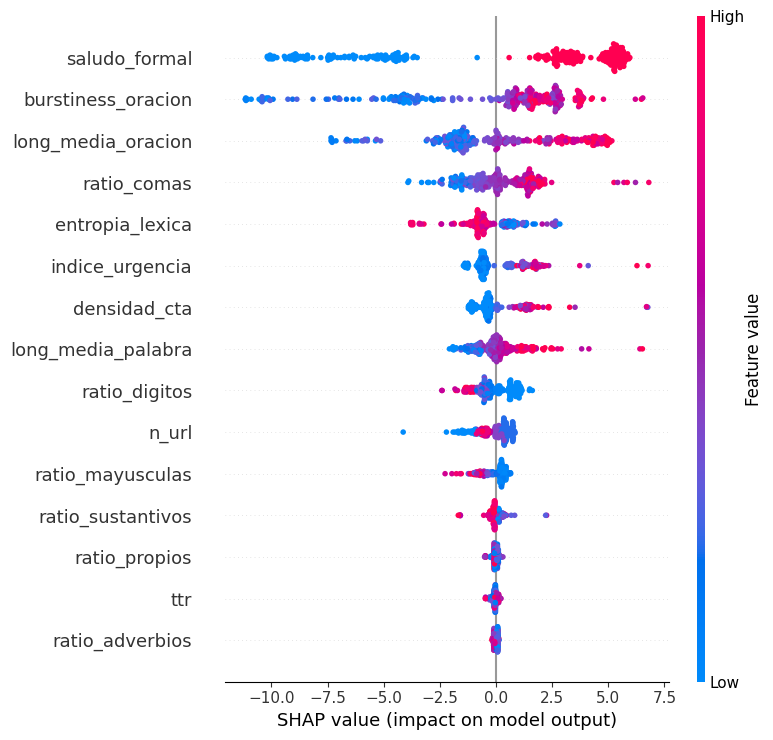

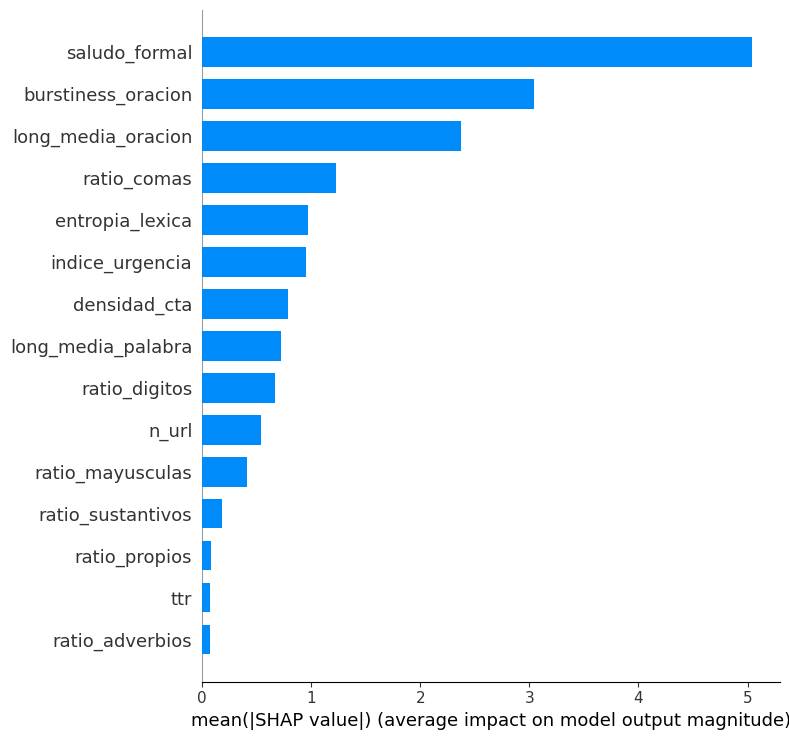

p = 27 | 1/p = 0.037 | 3/p = 0.1111


,shap_rel,gain_rel,nivel_shap,nivel_gain
rasgo,,,,
saludo_formal,0.289,0.392,Alto,Alto
burstiness_oracion,0.174,0.223,Alto,Alto
long_media_oracion,0.136,0.059,Alto,Medio
ratio_comas,0.070,0.046,Medio,Medio
entropia_lexica,0.056,0.069,Medio,Medio
indice_urgencia,0.055,0.034,Medio,Bajo
densidad_cta,0.045,0.053,Medio,Medio
long_media_palabra,0.042,0.042,Medio,Medio
ratio_digitos,0.038,0.019,Medio,Bajo


In [9]:
#9 Importancia de rasgos: SHAP y Gain

import shap
m = modelos()['LightGBM']
m.fit(X, y)
sv = shap.TreeExplainer(m).shap_values(X)
if isinstance(sv, list):
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:
    sv = sv[:, :, 1]

imp = pd.DataFrame({'rasgo': X.columns, 'shap_abs_media': np.abs(sv).mean(axis=0)}).sort_values('shap_abs_media', ascending=False)
imp.to_csv(f'{RES}/shap_importancia.csv', index=False)

plt.figure()
shap.summary_plot(sv, X, show=False, max_display=15)
plt.tight_layout()
plt.savefig(f'{RES}/shap_summary.png', dpi=200)
plt.show()

plt.figure()
shap.summary_plot(sv, X, plot_type='bar', show=False, max_display=15)
plt.tight_layout()
plt.savefig(f'{RES}/shap_barras.png', dpi=200)
plt.show()

gain = pd.Series(m.booster_.feature_importance(importance_type='gain'), index=X.columns)
gain_rel = gain / gain.sum()
shap_rel = imp.set_index('rasgo')['shap_abs_media']
shap_rel = shap_rel / shap_rel.sum()
p = len(X.columns)

def nivel(v):
    return 'Alto' if v > 3 / p else ('Medio' if v >= 1 / p else 'Bajo')

tabla_imp = pd.DataFrame({'shap_rel': shap_rel, 'gain_rel': gain_rel.loc[shap_rel.index]})
tabla_imp['nivel_shap'] = tabla_imp['shap_rel'].map(nivel)
tabla_imp['nivel_gain'] = tabla_imp['gain_rel'].map(nivel)
tabla_imp.to_csv(f'{RES}/importancia_relativa.csv')

print('p =', p, '| 1/p =', round(1 / p, 4), '| 3/p =', round(3 / p, 4))
tabla_imp.round(3).head(12)

In [10]:
#10. Tabla final de resultados

filas = []
for n, r in cv_res.items():
    g = r['global']
    fila = {'modelo': n}
    for k in ('recall', 'f1_macro', 'auc', 'fpr'):
        fila[k] = f"{g[k][0]:.3f} [{g[k][1]:.3f}, {g[k][2]:.3f}]"
    fila['delta_f1_prom'] = round(float(np.mean(list(delta[n].values()))), 4)
    fila['caida_recall_parafrasis'] = round(g['recall'][0] - r['para_recall'], 4) if 'para_recall' in r else np.nan
    fila['f1_cortos'] = round(r['cortos']['f1_macro'][0], 4) if 'cortos' in r else np.nan
    fila['f1_largos'] = round(r['largos']['f1_macro'][0], 4) if 'largos' in r else np.nan
    filas.append(fila)

tabla_final = pd.DataFrame(filas)
tabla_final.to_csv(f'{RES}/tabla_resultados.csv', index=False)
tabla_final

,modelo,recall,f1_macro,auc,fpr,delta_f1_prom,caida_recall_parafrasis,f1_cortos,f1_largos
0,LogReg,"0.960 [0.915, 0.985]","0.910 [0.873, 0.940]","0.965 [0.941, 0.986]","0.140 [0.089, 0.206]",0.0073,0.0800,0.8333,0.9426
1,RandomForest,"0.960 [0.915, 0.985]","0.876 [0.836, 0.912]","0.971 [0.954, 0.984]","0.207 [0.145, 0.280]",0.0148,0.0467,0.8887,0.8689
2,LightGBM,"0.953 [0.906, 0.981]","0.852 [0.811, 0.892]","0.965 [0.945, 0.983]","0.247 [0.180, 0.324]",0.0511,0.1067,0.8554,0.8486
3,XGBoost,"0.953 [0.906, 0.981]","0.876 [0.838, 0.913]","0.970 [0.951, 0.985]","0.200 [0.139, 0.273]",0.0308,0.0533,0.8554,0.8839
4,TFIDF_LogReg,"1.000 [0.976, 1.000]","0.957 [0.933, 0.980]","0.999 [0.998, 1.000]","0.087 [0.047, 0.144]",0.0000,0.0067,0.9778,0.9474


In [11]:
#11.	Análisis de errores y palabras funcionales
mejor = 'LightGBM'
pred = (oof[mejor] >= 0.5).astype(int)
err = corpus[['group', 'generator']].copy()
err['n'] = feats['n_palabras']
err['fp'] = (y == 0) & (pred == 1)
err['fn'] = (y == 1) & (pred == 0)
print('Falsos positivos por remitente:')
print(err[y == 0].groupby('group')['fp'].agg(['sum', 'count']).sort_values('sum', ascending=False).head(8))
print('Falsos positivos por rango de longitud:')
print(err[y == 0].groupby(pd.cut(err[y == 0]['n'], CORTES, labels=ETIQ))['fp'].agg(['sum', 'count']))
print('Falsos negativos por generador:')
print(err[y == 1].groupby('generator')['fn'].agg(['sum', 'count']))

palabras_funcionales = sorted(nlp.Defaults.stop_words)
def func_words():
    return make_pipeline(
        TfidfVectorizer(vocabulary=palabras_funcionales, sublinear_tf=True),
        LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    )

oof_fw = np.zeros(len(y))
for tr, te in cv.split(X, y, grupos):
    m = func_words()
    m.fit(corpus['text'].iloc[tr], y[tr])
    oof_fw[te] = m.predict_proba(corpus['text'].iloc[te])[:, 1]
r = resumen(y, (oof_fw >= 0.5).astype(int), oof_fw)
print('Palabras funcionales (estilo sin tema): recall=%.3f f1=%.3f auc=%.3f fpr=%.3f' % (r['recall'][0], r['f1_macro'][0], r['auc'][0], r['fpr'][0]))

Falsos positivos por remitente:
           sum  count
group                
G031d29f1   23     46
Gfde6eff2    7     48
G97fd2ef4    3      7
G2b72c7d7    1     10
G3cfd6d47    1      1
Gc0a894bc    1      1
Gc991b336    1      1
G12f29a85    0      1
Falsos positivos por rango de longitud:
         sum  count
n                  
0-40       7     37
40-70      1     15
70-100     6     18
100-130    5     24
130-170   10     33
170+       8     23
Falsos negativos por generador:
           sum  count
generator            
gemma        2     50
mistral      2     51
qwen         3     49
Palabras funcionales (estilo sin tema): recall=0.913 f1=0.893 auc=0.958 fpr=0.127


In [12]:
#12. Análisis de sensibilidad por remitente
excl = 'G031d29f1'
mask = (corpus['group'] != excl).values
filas = []
for n in nombres:
    pred = (oof[n] >= 0.5).astype(int)
    r = resumen(y[mask], pred[mask], oof[n][mask])
    filas.append({'modelo': n, **{k: f"{r[k][0]:.3f} [{r[k][1]:.3f}, {r[k][2]:.3f}]" for k in ('recall', 'f1_macro', 'auc', 'fpr')}})
print(mask.sum(), 'documentos;', int((y[mask] == 0).sum()), 'legítimos')
pd.DataFrame(filas)

254 documentos; 104 legítimos


,modelo,recall,f1_macro,auc,fpr
0,LogReg,"0.960 [0.915, 0.985]","0.926 [0.893, 0.956]","0.959 [0.927, 0.985]","0.115 [0.061, 0.193]"
1,RandomForest,"0.960 [0.915, 0.985]","0.947 [0.917, 0.972]","0.989 [0.979, 0.996]","0.067 [0.027, 0.134]"
2,LightGBM,"0.953 [0.906, 0.981]","0.914 [0.877, 0.947]","0.977 [0.957, 0.991]","0.135 [0.076, 0.216]"
3,XGBoost,"0.953 [0.906, 0.981]","0.918 [0.883, 0.951]","0.982 [0.967, 0.993]","0.125 [0.068, 0.204]"
4,TFIDF_LogReg,"1.000 [0.976, 1.000]","0.992 [0.979, 1.000]","1.000 [1.000, 1.000]","0.019 [0.002, 0.068]"


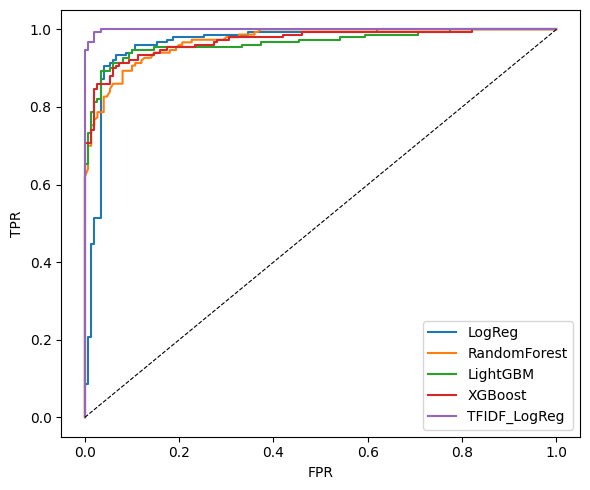

,modelo,TPR@FPR=5%,TPR@FPR=10%
0,LogReg,0.907,0.947
1,RandomForest,0.833,0.907
2,LightGBM,0.893,0.947
3,XGBoost,0.860,0.920
4,TFIDF_LogReg,1.000,1.000


In [13]:
#13 Curvas ROC y TPR@FPR

from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(6, 5))
filas = []
for n in nombres:
    fpr_, tpr_, _ = roc_curve(y, oof[n])
    ax.plot(fpr_, tpr_, label=n)
    filas.append({'modelo': n, 'TPR@FPR=5%': float(np.interp(0.05, fpr_, tpr_)), 'TPR@FPR=10%': float(np.interp(0.10, fpr_, tpr_))})
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RES}/roc.png', dpi=200)
plt.show()
pd.DataFrame(filas).round(3)

In [14]:
#14. Generalización a escenarios no vistos

grupo_esc = np.where(y == 1, corpus['group'].str.split('|').str[0], corpus['group'])
cv_esc = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
oof_e = {n: np.zeros(len(y)) for n in nombres}
for tr, te in cv_esc.split(X, y, grupo_esc):
    for n, m in modelos().items():
        m.fit(X.iloc[tr], y[tr])
        oof_e[n][te] = m.predict_proba(X.iloc[te])[:, 1]
    b = baseline()
    b.fit(corpus['text'].iloc[tr], y[tr])
    oof_e['TFIDF_LogReg'][te] = b.predict_proba(corpus['text'].iloc[te])[:, 1]

for n in nombres:
    r = resumen(y, (oof_e[n] >= 0.5).astype(int), oof_e[n])
    print(f"{n:14s} recall={r['recall'][0]:.3f} f1={r['f1_macro'][0]:.3f} auc={r['auc'][0]:.3f} fpr={r['fpr'][0]:.3f}")

LogReg         recall=0.960 f1=0.910 auc=0.956 fpr=0.140
RandomForest   recall=0.947 f1=0.842 auc=0.961 fpr=0.260
LightGBM       recall=0.940 f1=0.842 auc=0.955 fpr=0.253
XGBoost        recall=0.913 f1=0.843 auc=0.953 fpr=0.227
TFIDF_LogReg   recall=0.947 f1=0.933 auc=0.983 fpr=0.080


In [15]:
#15 Ablación del rasgo saludo_formal
X_sin = X.drop(columns=['saludo_formal'])
oof_sin = {}
for n in ['LightGBM', 'XGBoost', 'RandomForest', 'LogReg']:
    p_oof = np.zeros(len(y))
    for tr, te in cv.split(X_sin, y, grupos):
        mm = modelos()[n]
        mm.fit(X_sin.iloc[tr], y[tr])
        p_oof[te] = mm.predict_proba(X_sin.iloc[te])[:, 1]
    oof_sin[n] = p_oof

filas = []
for n in oof_sin:
    for etiqueta, sc in [('con saludo_formal', oof[n]), ('sin saludo_formal', oof_sin[n])]:
        pred = (sc >= 0.5).astype(int)
        met = puntuales(y, pred, sc)
        filas.append({'modelo': n, 'variante': etiqueta, **{k: round(v, 3) for k, v in met.items()}})
ablacion = pd.DataFrame(filas)
ablacion.to_csv(f'{RES}/ablacion_saludo_formal.csv', index=False)
ablacion

,modelo,variante,recall,f1_macro,fpr,auc
0,LightGBM,con saludo_formal,0.953,0.852,0.247,0.965
1,LightGBM,sin saludo_formal,0.973,0.862,0.247,0.959
2,XGBoost,con saludo_formal,0.953,0.876,0.200,0.970
3,XGBoost,sin saludo_formal,0.960,0.824,0.307,0.951
4,RandomForest,con saludo_formal,0.960,0.876,0.207,0.971
5,RandomForest,sin saludo_formal,0.973,0.834,0.300,0.953
6,LogReg,con saludo_formal,0.960,0.910,0.140,0.965
7,LogReg,sin saludo_formal,0.960,0.876,0.207,0.945


In [16]:
import shutil, os
from google.colab import files
shutil.make_archive('/content/resultados_completos', 'zip', RES)
print(sorted(os.listdir(RES)))
files.download('/content/resultados_completos.zip')

['ablacion_saludo_formal.csv', 'delta_f1.csv', 'importancia_relativa.csv', 'roc.png', 'shap_barras.png', 'shap_importancia.csv', 'shap_summary.png', 'tabla_resultados.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>